# Outlook

There is **almost no reinforcement learning** in this notebook. Before
writing algorithms, it is worth spending a session on what they act upon: an
*environment*, the way it presents information to the agent, and how data
is gathered from it.

We meet the infrastructure used throughout the course — gymnasium
environments, `VecEnv`, the actors, and the three collectors —
`TransitionCollector`, `EpisodeCollector`, `RolloutCollector` — and, once
the pieces are in place, train the first learning agent of the course,
tabular **Q-learning**, the one algorithm that can be written in a handful
of lines given that infrastructure.

The notebook then closes on a single maze, given to the agent under three
different disguises without changing the problem at all. The same problem
can be described in many ways, and that choice matters more than it looks
— it decides what the agent is even able to represent.

Small exercises are scattered through the notebook, marked **Exercise**:
the cells that follow them do not run until they are completed.

In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
import rl_mind.mazemdp_env
from torch import Tensor
from rl_mind.core import Action, Actor
from rl_mind.env import VecEnv
from rl_mind.data import Episode, Transitions
from rl_mind.collectors import EpisodeCollector, RolloutCollector, TransitionCollector
from rl_mind import RenderWidget, DecimateTrimmer
from rl_mind.notebook import silence_known_warnings


Matplotlib backend: module://matplotlib_inline.backend_inline


## The `rl_mind` toolkit

The `rl_mind` package ([documentation](https://master-dac.isir.upmc.fr/rl/rl-mind/)),
installed with the practicals, provides the pieces we are going to look at:

- `VecEnv` runs several copies of a gymnasium environment in parallel and
  uses **torch tensors** (similar to numpy ndarrays);
- `Actor` is the base class of every policy of the course, and `Action` what
  it returns;
- the three collectors (`TransitionCollector`, `EpisodeCollector`,
  `RolloutCollector`) run an actor in a `VecEnv` and each return a different
  shape of data.

The goal of this notebook is to:

1. Show what is an RL environment (handled by gymnasium);
2. Show how `rl_mind` can help you to interact with those environments in an RL setting;
3. Describe the different ways to collect data to train your agents

In [2]:
# pygame and tensorboard still use the deprecated `pkg_resources` API
silence_known_warnings()

# 1. RL environments – gymnasium

A [gymnasium](https://gymnasium.farama.org/) environment exposes very little:
two **spaces** describing what it accepts and what it returns, and two
methods, `reset` and `step`. Everything else — a maze, a pendulum, a video
game — hides behind that contract.

Let us look at two environments that could hardly be more different, `CartPole-v1` and `MazeMDP-v0`.

In [3]:
MAZE = {
    "width": 5,
    "height": 5,
    "ratio": 0.2,
    # a seeded maze: every copy built from this description is the same one
    "seed": 2,
    # always start in the same cell, so that the views below are comparable
    "start_states": [0],
}

for name, make_kwargs in [("CartPole-v1", {}), ("MazeMDP-v0", {"kwargs": MAZE})]:
    env = gym.make(name, **make_kwargs)
    print(f"{name}")
    print(f"    observations: {env.observation_space}")
    print(f"    actions     : {env.action_space}")

CartPole-v1
    observations: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
    actions     : Discrete(2)
MazeMDP-v0
    observations: Discrete(20)
    actions     : Discrete(4)


Two families of spaces show up here:

- `Box(low, high, shape, dtype)` — a vector of real numbers. For `CartPole` the four
  numbers are the position and velocity of the cart, the angle and angular
  velocity of the pole.
- `Discrete(n)` — a single integer in $\{0, \ldots, n-1\}$. For the maze it
  is the number of the cell the agent stands on, and for the actions of both
  environments it is the number of the chosen action.

## Interacting with an environment

`reset()` starts an episode and returns a first observation; `step(action)`
returns the next observation, the reward, and **two** distinct flags. Here
we use `env.action_space.sample()` since we don't have an agent – this samples
using a uniform distribution for each component.

In [4]:
env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)
print(f"first observation: {obs}")

action = env.action_space.sample()
print(f"Sampled action: {action} in {env.action_space}")
obs, reward, terminated, truncated, info = env.step(action)
print(f"after one step   : {obs}")
print(f"reward {reward}, terminated {terminated}, truncated {truncated}")

first observation: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Sampled action: 1 in Discrete(2)
after one step   : [ 0.01323574  0.17272775 -0.04686959 -0.3551522 ]
reward 1.0, terminated False, truncated False


`terminated` and `truncated` both end the episode, but they do not mean the
same thing, and confusing them is a classic source of silent bugs:

- **`terminated`** — the episode reached a real terminal state (the pole
  fell). There is no future: whatever the agent would have done next is
  worth nothing (reward is 0).
- **`truncated`** — the episode was cut short from the outside, typically by
  a time limit. The agent could have continued, and the future is *not*
  worth nothing.

Every algorithm of the course relies on that distinction to decide whether
to *bootstrap*, i.e. whether to use the value of the state that follows.

Let us watch it happen: `CartPole-v1` is limited to 500 steps, so a policy
good enough to survive that long gets `truncated`, while a bad one gets
`terminated` early.

**Exercise.** A policy is a function from an observation to an action.
Complete `react_to_the_pole` below so that the cart pushes in the direction
the pole is falling (action 1 pushes right).

The observation is
`[position, velocity, angle, angular velocity]`: position (m) and velocity
(m/s) describe the cart, angle (**radians**, positive = leaning right) and
angular velocity (rad/s) describe the pole. **The angle alone is not always
enough to tell which way the pole is going**: it can be leaning right while
already swinging back left, so also look at how fast it is rotating. Once
the two flags differ between the two policies, you have a policy that
survives the time limit.

Note: `react_to_the_pole` reacts to a single observation — a plain
`np.ndarray`, no batch. There is only one environment here; once `VecEnv`
shows up in part 2, every actor of the course reacts to a *batch* of
observations (one row per environment) at once.

In [4]:
def always_push_right(obs: np.ndarray) -> int:
    return 1


def react_to_the_pole(obs: np.ndarray) -> int:
    # obs = [position, velocity, angle (rad), angular velocity (rad/s)]
    # The output is an integer:
    # - 0: Push cart to the left
    # - 1: Push cart to the right
    #
    # Push towards the side the pole is falling to

    return (obs[2] > 0).astype(int)

def react_to_pole_and_velocity(obs: np.ndarray) -> int:
    vel_threshold = 1
    if obs[2] > 0:
        if obs[3] >= - vel_threshold:
            res = 1
        else:
            res = 0
    else:
        if obs[3] <=  vel_threshold:
            res = 0
        else:
            res = 1
    
    return res



for policy in [always_push_right, react_to_the_pole, react_to_pole_and_velocity]:
    env = gym.make("CartPole-v1")
    obs, _ = env.reset(seed=1)
    steps, terminated, truncated = 0, False, False
    while not (terminated or truncated):
        obs, _, terminated, truncated, _ = env.step(policy(obs))
        steps += 1
    ending = "terminated (the pole fell)" if terminated else "truncated (time limit)"
    print(f"{policy.__name__:>18}: {steps:>3} steps, {ending}")

 always_push_right:   9 steps, terminated (the pole fell)
 react_to_the_pole:  51 steps, terminated (the pole fell)
react_to_pole_and_velocity: 500 steps, truncated (time limit)


# 2. `VecEnv`: many copies, and tensors

Reinforcement learning needs a *lot* of interaction, and a single environment
stepped one action at a time is a poor use of a machine. `VecEnv` runs
`num_envs` independent copies of an environment and steps them together.

It also converts everything to **torch tensors**, so that the data can be fed
to a neural network without any bookkeeping. The leading dimension is always
the number of environments.

Note also that we use visualization helpers from the `rl_mind` library, that you
can use to visualize better what an agent is doing when working with
environments (at least those that provide image outputs).

In [6]:
env = RenderWidget(
    gym.make("CartPole-v1", render_mode="rgb_array"),
    trimmer=DecimateTrimmer(100, keep_ratio=0.5),
)
obs, _ = env.reset(seed=1)
terminated, truncated = False, False
while not (terminated or truncated):
    obs, reward, terminated, truncated, _ = env.step(react_to_the_pole(obs))

`step` returns an `EnvStep`, which carries `obs`, `next_obs`, `reward`,
`terminated` and `truncated` (plus `done`, which is simply
`terminated | truncated`), one entry per environment.

Why both `obs` and `next_obs`? Because when an episode ends in one of the
copies, that copy is **reset automatically** — otherwise the whole batch
would have to wait for the slowest episode — and the observation you should
*act* on next is no longer the observation that *followed* the last action.
`VecEnv` keeps the two apart:

- `next_obs` is the true successor $s_{t+1}$, the one the algorithms need to
  compute a value;
- `obs` is what to act upon at the next step.

## A minimal torch toolbox

The exercises of this notebook only ever need a handful of tensor
operations. If `torch` is new to you, here is the short list — everything
below is a 1-D tensor, one entry per environment:

- `torch.zeros(n)`, `torch.full((n,), value)`, `torch.randint(low, high,
  (n,))`, `torch.rand(n)` — create tensors: zeros, a repeated constant,
  random integers, random floats in $[0, 1)$.
- `t[mask]` / `t[i, j]` — index or mask a tensor like a numpy array; a
  *boolean* tensor used as an index keeps only the `True` entries.
- `torch.where(cond, a, b)` — element-wise "if / else": `a` where `cond` is
  `True`, `b` elsewhere.
- `t.sum()`, `t.max(dim)` — reduce along a dimension; `t.max(-1).values` is
  the max over the last axis, `.indices` the corresponding `argmax`.
- `~t` — logical *not* on a boolean tensor (e.g. `~terminated`).
- `q.index_put_((row_idx, col_idx), value, accumulate=True)` — add `value`
  into `q[row_idx, col_idx]` entry by entry, summing contributions when an
  index repeats in the batch (used once, in the Q-learning update).

The [PyTorch documentation](https://pytorch.org/docs/stable/torch.html) has
more detail on any of these if you need it.

**Exercise.** Run 200 random steps in the four environments and count the
episodes that end along the way, using the `done` flags (a boolean tensor —
see `t.sum()` above). A random policy keeps the pole up for about 20 steps:
how many episodes do you expect?

In [4]:
env = VecEnv("CartPole-v1", num_envs=4, seed=0)
env.reset()
n_ended = 0
for _ in range(200):
    step = env.step(torch.randint(0, env.n_actions, (env.num_envs,)))
    # Count the episodes that end at this step

    n_ended += step.done.sum()

print(f"{n_ended} episodes ended in {200 * env.num_envs} steps")

35 episodes ended in 800 steps


# 3. Collecting data

Since there is no learning yet, we need a policy that does not learn: one
that acts at random. Every policy of the course derives from `Actor`, and
returns an `Action`. An actor has two behaviours: `actor(obs)` (the
`forward` method) is the **training** behaviour, which may explore, and
`actor.act(obs)` is the deterministic **evaluation** behaviour. For a random
actor the two are the same.

In [5]:
class RandomActor(Actor[Action]):
    """Picks an action uniformly at random, for a batch of observations"""

    def __init__(self, n_actions: int):
        super().__init__()
        self.n_actions = n_actions

    def forward(self, obs: Tensor) -> Action:
        return Action(value=self.act(obs))

    def act(self, obs: Tensor) -> Tensor:
        return torch.randint(0, self.n_actions, (len(obs),))

## Automatic resets

Running an actor in an environment and *storing* what happens is the job of a
**collector**. Before meeting them, one detail of `VecEnv` has to be settled,
because the collectors depend on it: what exactly happens on the step where
an episode ends and the copy is reset. There are two ways of doing it:

- **next-step reset** (the default): the ending step returns the last
  observation of the finished episode, and the *following* step ignores the
  action it is given and returns the first observation of a fresh episode.
  That following step is not a valid transition, and has to be discarded.
- **same-step reset** (`same_step_reset=True`): the ending step already
  returns the first observation of the new episode in `obs`, while `next_obs`
  holds the last observation of the episode that just ended. **Every** step is
  then a valid transition.

The first mode is the natural one when the data is stored transition by
transition or episode by episode: one can simply skip the invalid step. The
second one is needed when the data must form a dense block of consecutive
steps, with no hole in it — which is what the on-policy methods (A2C, PPO)
need, as we will see.

In [6]:
for same_step in [False, True]:
    env = VecEnv("CartPole-v1", num_envs=1, seed=0, same_step_reset=same_step)
    env.reset()

    # push right until the pole falls, and look at the step that ends the episode
    step = env.step(torch.ones(1, dtype=torch.int64))
    while not step.done[0]:
        step = env.step(torch.ones(1, dtype=torch.int64))

    mode = "same-step" if same_step else "next-step"
    print(f"{mode} reset, on the step that ends the episode:")
    print(f"    next_obs (the successor s_t+1) : {step.next_obs[0].numpy().round(3)}")
    print(f"    obs      (what to act on next) : {step.obs[0].numpy().round(3)}")

next-step reset, on the step that ends the episode:
    next_obs (the successor s_t+1) : [ 0.12   1.545 -0.228 -2.605]
    obs      (what to act on next) : [ 0.12   1.545 -0.228 -2.605]
same-step reset, on the step that ends the episode:
    next_obs (the successor s_t+1) : [ 0.12   1.545 -0.228 -2.605]
    obs      (what to act on next) : [0.031 0.041 0.011 0.023]


## The three collectors

There are three collectors, and they differ in the shape of the data they
return — because the three families of algorithms need different things:

| collector | returns | reset mode | for |
|---|---|---|---|
| `TransitionCollector` | a flat batch of transitions | next-step (invalid steps are dropped) | off-policy (DQN, DDPG, SAC): the data goes into a replay buffer and gets shuffled, so the order does not matter |
| `EpisodeCollector` | complete episodes | next-step (invalid steps are dropped) | episodic methods (REINFORCE), which need the return of a whole episode |
| `RolloutCollector` | a `[T, B]` block | **same-step** (required) | on-policy methods (A2C, PPO), which walk *backwards* over time and therefore need the time axis intact |

In [7]:
env = VecEnv("CartPole-v1", num_envs=4, seed=0)
actor = RandomActor(env.n_actions)

transitions = TransitionCollector(env, actor).collect(n_steps=50)
print(f"TransitionCollector: {len(transitions)} transitions")
print(
    f"    obs {tuple(transitions.obs.shape)} | action "
    f"{tuple(transitions.action.value.shape)} | reward "
    f"{tuple(transitions.reward.shape)}"
)

episodes = EpisodeCollector(VecEnv("CartPole-v1", 4, seed=0), actor).collect(
    n_episodes=4
)
print(
    f"EpisodeCollector: {len(episodes)} episodes, "
    f"of lengths {[len(e) for e in episodes]}"
)
print(
    f"    the first one: obs {tuple(episodes[0].obs.shape)}, "
    f"cumulated reward {episodes[0].cumulated_reward}"
)

rollout = RolloutCollector(
    VecEnv("CartPole-v1", 4, seed=0, same_step_reset=True), actor
).collect(n_steps=10)
print(f"RolloutCollector: obs {tuple(rollout.obs.shape)}  (time, envs, features)")
print(f"    flattened: {tuple(rollout.flatten().obs.shape)}")

TransitionCollector: 192 transitions
    obs (192, 4) | action (192,) | reward (192,)
EpisodeCollector: 4 episodes, of lengths [14, 17, 24, 9]
    the first one: obs (14, 4), cumulated reward 14.0
RolloutCollector: obs (10, 4, 4)  (time, envs, features)
    flattened: (40, 4)


Notice the shapes. `TransitionCollector` returns **fewer** than
`n_steps * num_envs` transitions: it silently drops the invalid steps that
follow an automatic reset. `RolloutCollector` cannot afford to drop anything,
since that would punch holes in its `[T, B]` block — which is why it demands
`same_step_reset=True`.

All of these are `TensorStruct`s: they can be indexed, sliced and masked like
a tensor, but each field keeps its name and its type.

In [10]:
print(f"one transition   : {tuple(transitions[0].obs.shape)}")
print(f"the first three  : {tuple(transitions[:3].obs.shape)}")
print(f"the terminal ones: {len(transitions[transitions.terminated])}")

one transition   : (4,)
the first three  : (3, 4)
the terminal ones: 8


**Exercise.** Over 200 steps of a fresh `TransitionCollector` on 4
environments, compute the number of dropped steps and the number of terminal
transitions that were recorded. Explain how the two are related, and why
they may differ by a few units.

In [29]:
env = VecEnv("CartPole-v1", num_envs=4, seed=0)
transitions = TransitionCollector(env, RandomActor(env.n_actions)).collect(n_steps=200)
# The dropped steps and the terminal transitions

n_dropped = 200 * 4 - len(transitions.obs)
n_terminal = transitions.terminated.sum()

print(f"dropped steps {n_dropped}, terminal transitions {n_terminal}")

dropped steps 33, terminal transitions 33


**Exercise.** `RandomActor` ignores its observations. Write an actor for the
maze that always plays the same action (one call to `torch.full`, see the
toolbox in part 2, does it), and use `EpisodeCollector` to measure how long
its episodes last. What do you expect, and what do you observe? (Remember
the time limit met in part 1.)

In [6]:
class ConstantActor(Actor[Action]):
    """Always plays the same action"""

    def __init__(self, action: int):
        super().__init__()
        self.action = action

    def forward(self, obs: Tensor) -> Action:
        return Action(value=self.act(obs))

    def act(self, obs: Tensor) -> Tensor:
        # The same action for every observation of the batch

       return torch.full(size=(len(obs),), fill_value=self.action)



env = VecEnv("MazeMDP-v0", num_envs=2, seed=0, kwargs=MAZE)
for action in range(env.n_actions):
    episodes = EpisodeCollector(env, ConstantActor(action)).collect(n_episodes=2)
    print(f"action {action}: episodes of lengths {[len(e) for e in episodes]}")

action 0: episodes of lengths [200, 200]
action 1: episodes of lengths [200, 200]
action 2: episodes of lengths [200, 200]
action 3: episodes of lengths [200, 200]


Every action hits the 200-step limit without a single `terminated=True`:
this is not a bug, the constant action walks the agent into a wall after a
step or two and it stays there, so it never reaches the goal. Seeing it
helps: below is one constant-action episode, rendered with the maze's own
notebook widget (lighter than `RenderWidget`, which is meant for
environments — like `CartPole` above — that only render as images).

In [16]:
maze = gym.make("MazeMDP-v0", kwargs=MAZE, render_mode="human").unwrapped
maze.reset()
maze.init_draw("A constant action")
for _ in range(15):
    maze.step(1)
    maze.render()

# 4. A first learning agent: Q-learning

We now have an environment, several copies of it, an actor and three ways of
collecting data. What is missing is an actor that *learns*. The simplest one
is tabular **Q-learning**, and it fits the infrastructure in a handful of
lines.

Q-learning keeps a table $Q(s, a)$ with one entry per state and action —
which is only possible with the *native* view of the maze (an observation is
the integer index of the cell, as introduced in part 1), which indexes the
table directly. For a transition
$(s, a, r, s')$, the entry is moved towards the bootstrapped target:

$$ Q(s, a) \leftarrow Q(s, a) + \alpha\,\big[\, r + \gamma\,(1 -
\text{terminated})\,\max_{a'} Q(s', a') - Q(s, a) \,\big] $$

where $\alpha$ is the learning rate. When $s'$ is **terminal**, there is no
future and the bootstrap term is dropped — this is the `terminated` flag
of part 1 at work. Note that the maze has a time limit of 200 steps: an
episode cut by it is *truncated*, not terminated, and its last transition
bootstraps like any other.

## The actor

The actor owns the table. Its two behaviours are now different: in
training it explores with an **$\epsilon$-greedy** rule (a random action
with probability $\epsilon$, the greedy one otherwise), and in evaluation
(`act`) it is greedy.

**Exercise.** Complete `forward`. Everything is batched: `obs` holds one
state per environment, and the returned `Action` one action per
environment. You will need `torch.randint` (as in `RandomActor` above),
`torch.rand` (uniform distribution) to draw the exploration mask, and `torch.where`, which picks
between two tensors element-wise (see the toolbox in part 2).

Note that you will work with **batches** - and one of the goals of this
exercise is to get used to do so, using batched operations and masks.

In [7]:
class QTableActor(Actor[Action]):
    """An epsilon-greedy actor over a Q-table"""

    def __init__(self, n_states: int, n_actions: int, epsilon: float):
        super().__init__()
        self.q = torch.zeros(n_states, n_actions)
        self.epsilon = epsilon
        self.n_states = n_states
        self.n_actions = n_actions

    def act(self, obs: Tensor) -> Tensor:
        """The greedy action of every state in `obs`"""
        return self.q[obs].argmax(-1)

    def forward(self, obs: Tensor) -> Action:
        # Epsilon-greedy: random with probability epsilon, greedy otherwise

        greedy = self.act(obs)
        random = torch.randint(low=0, high=self.n_actions, size=(len(obs),))
        explore = torch.full(size=(len(obs),), fill_value=self.epsilon) < torch.rand(size=(len(obs),))
        return Action(value=torch.where(explore, random, greedy))

In [8]:
X = torch.tensor([
    [1, 2],
    [3, 4]
])
print(X)

X.index_put_((torch.tensor([1], dtype=torch.long), torch.tensor([1], dtype=torch.long)),torch.tensor([5]), accumulate = True)

print(X)

tensor([[1, 2],
        [3, 4]])
tensor([[1, 2],
        [3, 9]])


## The update

A `TransitionCollector` returns a batch of transitions at once, so the
update is written for a **batch**: every quantity below is a tensor with one
entry per transition, and the table is indexed with the tensors of states
and actions directly.

**Exercise.** Compute the target and the TD error. `q[batch.next_obs]`
indexes the table with a batch of states at once, giving one row of
$Q(s', \cdot)$ per transition; `.max(-1).values` reduces each row to its
max. `~batch.terminated` is the boolean mask, negated (see the toolbox in
part 2), that zeroes the bootstrap term for terminal transitions. The last
line applies the update; it uses `index_put_` with `accumulate=True`
because two transitions of the batch may share the same $(s, a)$, in which
case both corrections must be applied.

In [9]:
def q_learning_update(
    q: Tensor, batch: Transitions[Action], alpha: float, gamma: float
) -> Tensor:
    """Apply the Q-learning update to `q` for a batch of transitions

    :returns: the TD errors, shape `[N]`
    """
    state, action = batch.obs, batch.action.value
    # The bootstrapped target and the TD error (no bootstrap from a terminal state)

    q_next = q[batch.next_obs]
    target = batch.reward + gamma * ~batch.terminated * q_next.max(-1).values
    td_error = target - q[state, action]

    q.index_put_((state, action), alpha * td_error, accumulate=True)
    return td_error

## Evaluation

The reward of the maze is 1 when the goal is reached and 0 elsewhere, so the
cumulated reward says only *whether* the goal was reached. A better measure
of progress is the **length** of a greedy episode: it decreases as the
policy improves, and is capped by the time limit until the goal is found.

We measure it with the tools of part 3: `EpisodeCollector` runs an actor's
training behaviour, so we wrap the Q-table actor in an actor whose training
behaviour *is* the evaluation one.

In [10]:
class GreedyActor(Actor[Action]):
    """Runs the evaluation behaviour (`act`) of another actor"""

    def __init__(self, actor: Actor[Action]):
        super().__init__()
        self.actor = actor

    def forward(self, obs: Tensor) -> Action:
        return Action(value=self.actor.act(obs))

    def act(self, obs: Tensor) -> Tensor:
        return self.actor.act(obs)


def greedy_episode_length(actor: Actor[Action], env: VecEnv) -> float:
    """The mean length of one greedy episode per environment"""
    episodes = EpisodeCollector(env, GreedyActor(actor)).collect(env.num_envs)
    return float(np.mean([len(e) for e in episodes]))

## The training loop

Everything is in place. Each iteration performs **one step in every
environment**, updates the table with the resulting batch, and lowers
$\epsilon$ linearly from 1 to 0.05 over the first half of the training.
The number of environment steps is what we count: it is the cost of
training, and the budget every experiment below is given.

In [11]:
def train_q_learning(
    num_envs: int,
    total_steps: int,
    alpha: float = 0.5,
    gamma: float = 0.9,
    eval_every: int = 100,
    seed: int = 0,
):
    torch.manual_seed(seed)
    env = VecEnv("MazeMDP-v0", num_envs, seed=seed, kwargs=MAZE)
    eval_env = VecEnv("MazeMDP-v0", 1, seed=seed + 1, kwargs=MAZE)

    actor = QTableActor(env.n_states, env.n_actions, epsilon=1.0)
    collector = TransitionCollector(env, actor)
    history = []
    next_eval = 0
    while collector.steps < total_steps:
        batch = collector.collect(n_steps=1)
        q_learning_update(actor.q, batch, alpha, gamma)
        actor.epsilon = max(0.05, 1.0 - 2 * collector.steps / total_steps)

        if collector.steps >= next_eval:
            history.append((collector.steps, greedy_episode_length(actor, eval_env)))
            next_eval += eval_every
    return actor, history


# Uses 8000 steps (600 in fast test mode)
# TOTAL_STEPS = Profile.pick(8_000, fast_test=600)
TOTAL_STEPS = 8000
actor, history = train_q_learning(num_envs=4, total_steps=TOTAL_STEPS)
print(f"greedy episode length: {history[0][1]:.0f} -> {history[-1][1]:.0f} steps")

greedy episode length: 200 -> 9 steps


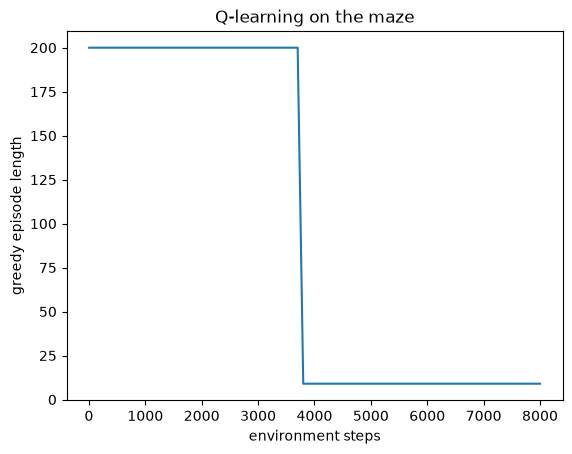

In [12]:
steps, lengths = zip(*history)
plt.plot(steps, lengths)
plt.xlabel("environment steps")
plt.ylabel("greedy episode length")
plt.title("Q-learning on the maze")
plt.show()

The learned table can be drawn on the maze itself: $V(s) = \max_a Q(s, a)$
as colours, and the greedy policy as arrows. Since the maze is seeded, a
fresh copy built for drawing is the very same maze the agent was trained
on.

In [13]:
maze = gym.make("MazeMDP-v0", kwargs=MAZE, render_mode="human").unwrapped
maze.reset()
maze.init_draw("The maze")
maze.draw_v_pi(
    actor.q.max(-1).values.numpy(), actor.q.argmax(-1).numpy(), title="Q-learning"
)

## Going further

This question is open-ended.

**Exercise (parallel environments).** Train with 1, 4 and 16 environments
for the same budget of environment steps and plot the three learning curves
against the number of steps. Does running more copies make the *learning*
faster, or only the *collection*? Give an argument: how many updates does
each transition get, and how many transitions does each update see?

In [ ]:
# Compare the learning curves for several values of num_envs

...
assert False, 'Not implemented yet'


# 5. Three collectors, one update

Part 3 introduced the three collectors by the *shape* of what they return,
on `CartPole`. Now that there is something to learn, we can ask a sharper
question on the maze: does it matter *which* collector feeds the very same
Q-learning update?

The update above only needs $(s, a, r, s', \text{terminated})$; it can
therefore be fed by any of the three collectors, provided their output is
turned into `Transitions`.

**Exercise.**

1. **Episodes.** Write `episode_to_transitions(episode)`. An `Episode`
   holds `obs` ($s_0 \ldots s_{T-1}$), `action`, `reward` and a single
   `terminated` flag for its last step; `episode.all_obs` gives
   $s_0 \ldots s_T$, so that `all_obs[1:]` are the successors. Build the
   `terminated` field with `torch.zeros(..., dtype=torch.bool)` (see the
   toolbox in part 2) and set its last entry. Then train with an
   `EpisodeCollector`, updating after each episode.
2. **Rollouts.** `rollout.flatten()` already carries the five fields, with
   the same names: it can be passed to `q_learning_update` as is. Train with
   a `RolloutCollector` — and remember which reset mode it demands.

Compare the three learning curves for the same number of environment steps.

transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Transitions'>
transition <class 'rl_mind.data.Tr

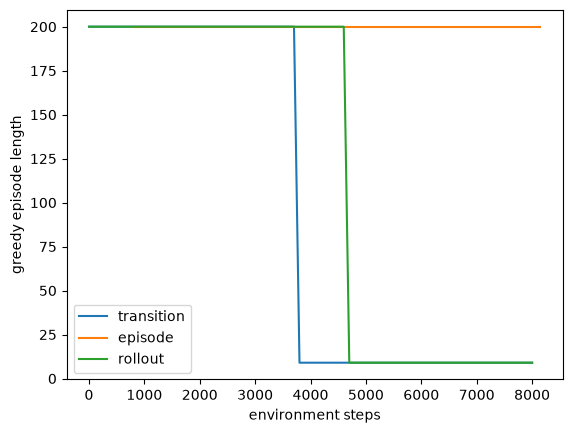

In [30]:
def episode_to_transitions(episode: Episode[Action]) -> Transitions[Action]:
    """The transitions of an episode, as a flat batch"""
    # Build the five fields; only the last step may be terminal

    terminated = torch.zeros(size=(len(episode.obs),), dtype=torch.bool)
    terminated[-1] = episode.terminated
    return Transitions(
        obs=episode.obs,
        action=episode.action,
        reward=episode.reward,
        next_obs=episode.all_obs[1:],
        terminated=terminated
        )


def train_q_learning_with(
    collector_name: str,
    num_envs: int,
    total_steps: int,
    alpha: float = 0.5,
    gamma: float = 0.9,
    eval_every: int = 100,
    seed: int = 0,
):
    """Q-learning fed by the collector named `collector_name`"""
    torch.manual_seed(seed)
    eval_env = VecEnv("MazeMDP-v0", 1, seed=seed + 1, kwargs=MAZE)
    # Create the environment (mind the reset mode) and the collector
    match collector_name:
        case "transition":
            env = VecEnv("MazeMDP-v0", num_envs, seed=seed, kwargs=MAZE)
            actor = QTableActor(env.n_states, env.n_actions, epsilon = 1.0)
            collector = TransitionCollector(env, actor)
        case "episode":

            env = VecEnv("MazeMDP-v0", num_envs, seed=seed, kwargs=MAZE)
            actor = QTableActor(env.n_states, env.n_actions, epsilon = 1.0)
            collector = EpisodeCollector(env, actor)
        case "rollout":
            env = VecEnv("MazeMDP-v0", num_envs, seed=seed, kwargs=MAZE, same_step_reset=True)
            actor = QTableActor(env.n_states, env.n_actions, epsilon = 1.0)
            collector = RolloutCollector(env, actor)
        case _:
            raise ValueError(f"Unknown collector type : {collector_name}")


    history = []
    next_eval = 0
    while collector.steps < total_steps:
        # Collect, and apply the update on the resulting batch(es)
        match collector_name:
            case "transition":
                batch = collector.collect(1)
            case "episode":
                episode = collector.collect(1)
                batch = episode_to_transitions(episode[0])
            case "rollout":
                batch = collector.collect(1)
            case _:
                raise ValueError(f"Unknown collector type : {collector_name}")
        print(collector_name, type(batch))
        q_learning_update(actor.q, batch, alpha, gamma)
        actor.epsilon = max(0.05, 1.0 - 2 * collector.steps / total_steps)

        if collector.steps >= next_eval:
            history.append((collector.steps, greedy_episode_length(actor, eval_env)))
            next_eval += eval_every
    return actor, history


for collector_name in ["transition", "episode", "rollout"]:
    _, history = train_q_learning_with(collector_name, 4, TOTAL_STEPS)
    steps, lengths = zip(*history)
    plt.plot(steps, lengths, label=collector_name)
plt.xlabel("environment steps")
plt.ylabel("greedy episode length")
plt.legend()
plt.show()

# 6. The same maze, three ways

The maze below is *one* problem: an agent walking on a grid. What changes
from one cell to the next is only **how a position is described** to the
agent — and that choice is not neutral, as we saw with the Q-table above,
which only works because it sees the state as a plain integer.

The trick is a gymnasium `ObservationWrapper`: it declares a new
observation space and translates each observation; `VecEnv` applies it to
every copy. The maze always starts in the same cell here, so the three
views below describe **the same state**: watch it turn into a number, then
a vector of zeros and ones, then two coordinates.

### a. As a state number (the native view)

The maze speaks `Discrete`: an observation is the index of the cell. `VecEnv`
turns it into a tensor of **integers**, which can index a table directly —
this is what the tabular algorithms use (and what part 4 does).

In [ ]:
env = VecEnv("MazeMDP-v0", num_envs=1, seed=0, kwargs=MAZE)
obs = env.reset()
print(f"observation: {obs}  {obs.dtype}")
print(f"n_states = {env.n_states}, n_actions = {env.n_actions}")

# a table with one row per state, read with the observations themselves
q_table = torch.zeros(env.n_states, env.n_actions)
print(f"q_table[obs] -> {tuple(q_table[obs].shape)}")

### b. As a one-hot vector

A neural network cannot take a state *number* as input: it would read an
order and a distance into it that do not exist. The usual translation is a
**one-hot** vector — as many components as states, all zero except a one at
the index of the current state. Nothing is lost or gained, it is the same
information, but the space becomes a `Box`. This wrapper is given; it is
the model for the one you will write next.

In [ ]:
class OneHotWrapper(gym.ObservationWrapper):
    """Present a `Discrete` observation as a one-hot `Box` vector"""

    def __init__(self, env):
        super().__init__(env)
        self.n_states = env.observation_space.n
        self.observation_space = gym.spaces.Box(
            0.0, 1.0, shape=(self.n_states,), dtype=np.float32
        )

    def observation(self, obs):
        one_hot = np.zeros(self.n_states, dtype=np.float32)
        one_hot[obs] = 1.0
        return one_hot

In [ ]:
env = VecEnv("MazeMDP-v0", num_envs=1, seed=0, kwargs=MAZE, wrappers=[OneHotWrapper])
obs = env.reset()
print(f"observation: {tuple(obs.shape)}  {obs.dtype}")
print(f"observation_dim = {env.observation_dim}")
print(obs)

### c. As coordinates

A third description: the $(x, y)$ position of the agent in the grid. Two
numbers instead of `n_states`, and this time they *do* carry a geometry —
two nearby cells have nearby coordinates, so a network can generalize from
one to the other. The unwrapped environment gives the coordinates of every
state in `coord_x` and `coord_y` (`env.unwrapped.coord_x[state]`). This
wrapper is given; the next one is for you to write.

In [ ]:
class CoordinatesWrapper(gym.ObservationWrapper):
    """Present a maze state as its $(x, y)$ position in the grid"""

    def __init__(self, env):
        super().__init__(env)
        maze = env.unwrapped
        # the coordinates are bounded by the extent of the grid
        size = float(max(maze.coord_x.max(), maze.coord_y.max()))
        self.observation_space = gym.spaces.Box(0.0, size, shape=(2,), dtype=np.float32)

    def observation(self, obs):
        maze = self.env.unwrapped
        return np.array([maze.coord_x[obs], maze.coord_y[obs]], dtype=np.float32)

In [ ]:
env = VecEnv(
    "MazeMDP-v0", num_envs=1, seed=0, kwargs=MAZE, wrappers=[CoordinatesWrapper]
)
obs = env.reset()
print(f"observation: {tuple(obs.shape)}  {obs.dtype}")
print(obs)

# take one step to the right and check that the coordinates move by one cell
step = env.step(torch.tensor([1]))
print(f"after one step: {step.obs}")

**Exercise.** Neural networks are happier with inputs of order 1. Write
`NormalizedCoordinatesWrapper`, which returns the same two coordinates
scaled between 0 and 1. Reuse `CoordinatesWrapper` (inherit from it) rather
than starting over. Why is this normalization usually preferable as the
input of a network?

In [ ]:
class NormalizedCoordinatesWrapper(CoordinatesWrapper):
    """Present a maze state as its $(x, y)$ position, scaled in $[0, 1]$"""

    def __init__(self, env):
        super().__init__(env)
        # The extent of the grid, and the new observation space

        self.size = ...
        self.observation_space = ...
        assert False, 'Not implemented yet'


    def observation(self, obs):
        # Scale the coordinates returned by `CoordinatesWrapper`

        # return ...
        assert False, 'Not implemented yet'


In [ ]:
env = VecEnv(
    "MazeMDP-v0",
    num_envs=1,
    seed=0,
    kwargs=MAZE,
    wrappers=[NormalizedCoordinatesWrapper],
)
print(f"observation: {env.reset()}")
print(f"space      : {env.observation_space}")

Three descriptions, one problem. Keep in mind that the choice is **not**
neutral: the state number makes tabular methods possible but forbids any
generalization; the one-hot vector allows a network without giving it
anything to generalize *with*; the coordinates make two neighbouring cells
look alike, which is what allows an agent to learn something about a state
it has never visited. Choosing what the agent sees is part of the problem,
not a detail of implementation.

(Real environments often go further and return several pieces at once — a
racing game gives the kart's position, the items on the track, the engine
state... gymnasium describes this with a `Dict` space, and `VecEnv` then
returns a `TensorStruct`, one named tensor field per key. We will not need
it in this course.)

# What's next

The table of part 4 has one row per state: it works because the maze is
tiny and because the agent sees the *state number*. Give it the coordinate
view of part 6c instead, and nothing indexes a table with two floats. The
next session replaces the table with a neural network that takes such
observations — Deep Q-Networks — and everything else in this notebook
stays as it is: the same `VecEnv`, the same actors, the same
`TransitionCollector`, the same `terminated` flag in the target.